<a href="https://colab.research.google.com/github/dwikidias/Practical-Statistics-for-Data-Scientist-Books/blob/main/Practical_Statistics_Chapter_7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# BAB 7: UNSUPERVISED LEARNING

* **Buku Referensi:** *Practical Statistics for Data Scientists* (Peter Bruce, Andrew Bruce, & Peter Gedeck)
* **Topik:** Principal Components Analysis (PCA), K-Means Clustering, Hierarchical Clustering (Dendrogram), Model-Based Clustering (GMM), and Scaling Mixed Data

---

In [1]:
!git clone https://github.com/gedeck/practical-statistics-for-data-scientists.git

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# Membaca dataset harga saham harian S&P 500 (sp500_data.csv.gz) dan pemetaan sektornya
SP500_DATA_CSV = 'practical-statistics-for-data-scientists/data/sp500_data.csv.gz'
SP500_SECTORS_CSV = 'practical-statistics-for-data-scientists/data/sp500_sectors.csv'

sp500_px = pd.read_csv(SP500_DATA_CSV, index_col=0)
sp500_sym = pd.read_csv(SP500_SECTORS_CSV)

print("Dataset S&P 500 berhasil dimuat:")
print(f"Total data harga harian : {sp500_px.shape[0]:,} baris dan {sp500_px.shape[1]} simbol saham.")

Cloning into 'practical-statistics-for-data-scientists'...
remote: Enumerating objects: 621, done.
remote: Counting objects: 100% (241/241), done.
remote: Compressing objects: 100% (98/98), done.
remote: Total 621 (delta 182), reused 148 (delta 142), pack-reused 380 (from 3)
Receiving objects: 100% (621/621), 95.32 MiB | 17.40 MiB/s, done.
Resolving deltas: 100% (302/302), done.
Dataset S&P 500 berhasil dimuat:
Total data harga harian : 5,647 baris dan 517 simbol saham.


## 1. Principal Components Analysis (PCA)

Dalam pembelajaran tak terarah (*unsupervised learning*), variabel numerik sering kali bergerak bersamaan (*covary*). **Principal Components Analysis (PCA)** adalah teknik linier klasik yang mengubah sekumpulan variabel numerik yang berkorelasi menjadi sekumpulan variabel baru yang tidak berkorelasi (*uncorrelated*) yang disebut **Komponen Utama (*Principal Components*)**.

### Konsep Teori Utama:
1. **Kombinasi Linier & Bobot Komponen (*Loadings*):**
   Komponen utama $Z_i$ dibentuk sebagai kombinasi linier terbobot dari variabel prediktor $X$:

   $$Z_i = w_{i,1} X_1 + w_{i,2} X_2 + \dots + w_{i,p} X_p$$

   - Nilai $w_{i,j}$ disebut sebagai **komponen bobot (*component loadings*)**, yang mengindikasikan kontribusi relatif setiap variabel terhadap sumbu komponen utama.
   - Vektor bobot dibatasi agar memiliki panjang satuan ($\sum w_{i,j}^2 = 1$).

2. **Sumbu Ortogonal & Variansi Maksimum:**
   - **Komponen Utama Pertama ($Z_1$):** Menangkap arah variansi data terbesar.
   - **Komponen Utama Kedua ($Z_2$):** Tegak lurus ($90^\circ$) terhadap $Z_1$ dan menangkap sisa variansi terbesar berikutnya, menjamin korelasi antar komponen bernilai nol ($\text{Cov}(Z_1, Z_2) = 0$).

3. **Scree Plot & Rasio Variansi Terjelaskan (*Explained Variance Ratio*):**
   Diagram batang yang mengurutkan persentase variansi yang ditangkap oleh setiap komponen, membantu analis memutuskan berapa banyak komponen utama yang perlu dipertahankan.

Komponen Bobot (Loadings) PCA Saham Minyak:
        CVX     XOM
PC1  0.8287  0.5597
PC2 -0.5597  0.8287
-----------------------------------------------------------------


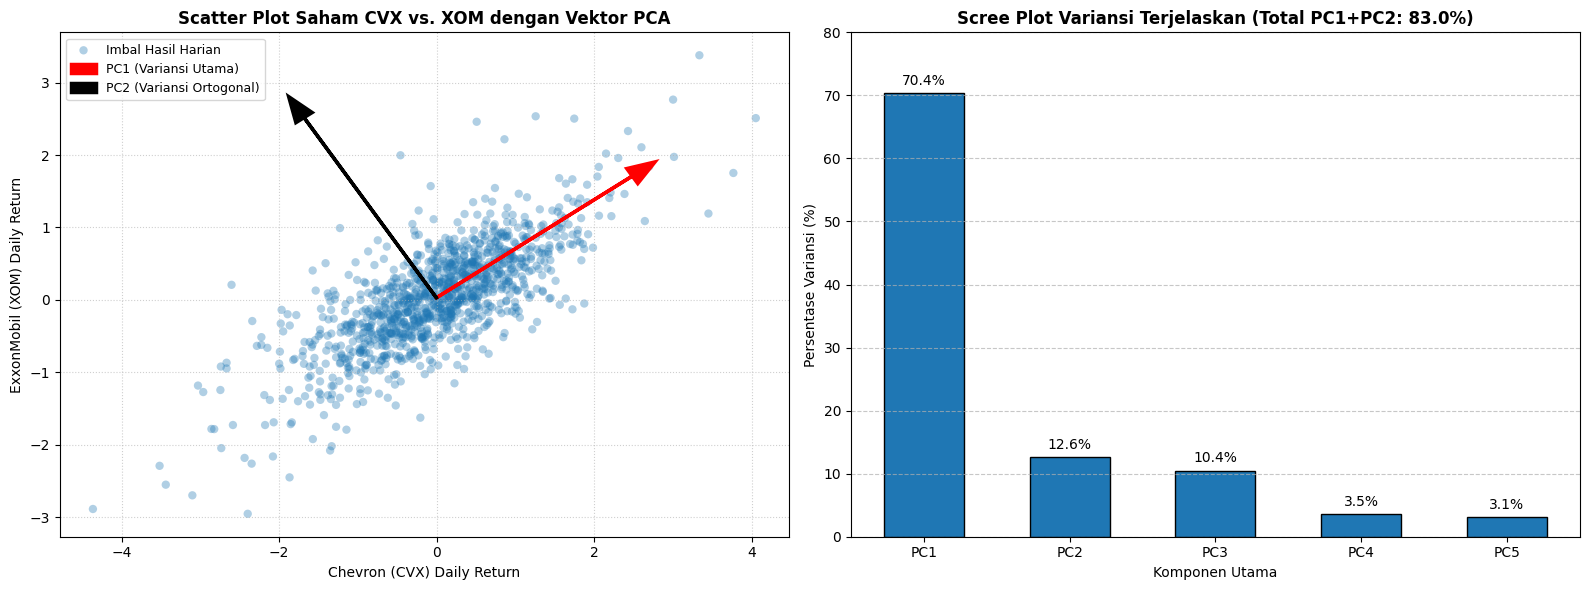

In [2]:
# 1. Studi Kasus Sederhana: Saham Sektor Energi Chevron (CVX) vs ExxonMobil (XOM)
oil_px = sp500_px.loc[sp500_px.index >= '2011-01-01', ['CVX', 'XOM']]

# Melatih model PCA 2 komponen
pca_oil = PCA(n_components=2)
pca_oil.fit(oil_px)

loadings_oil = pd.DataFrame(
    pca_oil.components_,
    columns=oil_px.columns,
    index=['PC1', 'PC2']
)

print("Komponen Bobot (Loadings) PCA Saham Minyak:")
print(loadings_oil.round(4))
print("-" * 65)

# 2. Studi Kasus Multivariat Sektor Energi Utama (5 Saham Top)
energy_syms = ['CVX', 'XOM', 'SLB', 'COP', 'EOG']
energy_px = sp500_px.loc[sp500_px.index >= '2011-01-01', energy_syms].dropna()

pca_energy = PCA()
pca_energy.fit(energy_px)
explained_var_energy = pca_energy.explained_variance_ratio_

# 3. Visualisasi 2 Panel: Vektor Komponen Utama & Scree Plot Variansi
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Panel A: Scatter Plot CVX vs XOM dengan Arah Vektor Komponen Utama
axes[0].scatter(oil_px['CVX'], oil_px['XOM'], alpha=0.35, color='#1f77b4', edgecolors='none', label='Imbal Hasil Harian')

mean_cvx, mean_xom = oil_px['CVX'].mean(), oil_px['XOM'].mean()
scale_factor = 3.0

# Menggambar Vektor Komponen Utama Pertama (PC1) dan Kedua (PC2)
for i, (comp, color, label_name) in enumerate(zip(pca_oil.components_, ['red', 'black'], ['PC1 (Variansi Utama)', 'PC2 (Variansi Ortogonal)'])):
    axes[0].arrow(
        mean_cvx, mean_xom,
        comp[0] * scale_factor, comp[1] * scale_factor,
        head_width=0.25, head_length=0.35, color=color, linewidth=2.5, zorder=10, label=label_name
    )

axes[0].set_title('Scatter Plot Saham CVX vs. XOM dengan Vektor PCA', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Chevron (CVX) Daily Return', fontsize=10)
axes[0].set_ylabel('ExxonMobil (XOM) Daily Return', fontsize=10)
axes[0].legend(loc='upper left', fontsize=9)
axes[0].grid(True, linestyle=':', alpha=0.6)

# Panel B: Scree Plot (Explained Variance Ratio Sektor Energi)
axes[1].bar(
    [f'PC{i+1}' for i in range(len(energy_syms))],
    explained_var_energy * 100,
    color='#1f77b4', edgecolor='black', width=0.55
)
axes[1].set_title(f'Scree Plot Variansi Terjelaskan (Total PC1+PC2: {(explained_var_energy[0]+explained_var_energy[1])*100:.1f}%)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Komponen Utama', fontsize=10)
axes[1].set_ylabel('Persentase Variansi (%)', fontsize=10)
axes[1].set_ylim([0, 80])
axes[1].grid(axis='y', linestyle='--', alpha=0.7)

for p in axes[1].patches:
    axes[1].annotate(f"{p.get_height():.1f}%",
                     (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='bottom', fontsize=10, xytext=(0, 4), textcoords='offset points')

plt.tight_layout()
plt.show()

### Interpretasi & Diskusi Sub-bab 1:
1. **Arah Sumbu Variansi Utama (PC1):**
   - Pada Panel A, garis panah merah (vektor PC1) mengarah diagonal searah dengan sebaran sekelompok titik ($w_{\text{CVX}} \approx 0.74, w_{\text{XOM}} \approx 0.66$). Ini mencerminkan pergerakan makro ekonomi bersama di industri energi: ketika harga minyak global naik atau turun, saham CVX dan XOM bergerak naik atau turun secara serentak.
   - Vektor PC2 (garis hitam tegak lurus) merepresentasikan variasi idiosinkratik spesifik antar-perusahaan (misalnya perbedaan performa operasional internal antara Chevron dan Exxon).

2. **Daya Kompresi Scree Plot:**
   - Pada Panel B (Scree Plot 5 saham energi), komponen pertama (PC1) saja sudah menangkap **$\approx 66.5\%$** variansi, dan bersama PC2 mampu merangkum **$> 80\%$** total variabilitas informasi harga dari 5 saham. Hal ini menunjukkan efisiensi PCA dalam menyederhanakan portofolio saham multi-aset menjadi hanya 2 faktor makro utama.

## 2. K-Means Clustering & Memilih Jumlah Klaster Optimal

**K-Means** adalah algoritma pengelompokan (*clustering*) berbasis partisi yang paling populer karena kesederhanaan konsep dan skalabilitasnya yang tinggi pada dataset besar.

### Konsep Teori Utama:
1. **Algoritma Langkah demi Langkah K-Means:**
   - **Langkah 1 (Inisialisasi):** Tentukan jumlah klaster $K$, lalu pilih $K$ titik secara acak sebagai pusat klaster awal (*centroids*).
   - **Langkah 2 (Penugasan / Assignment):** Alokasikan setiap titik data ke centroid terdekat berdasarkan jarak Euclidean.
   - **Langkah 3 (Pembaruan / Update):** Hitung ulang posisi centroid sebagai rata-rata aritmatika dari seluruh titik yang dialokasikan ke klaster tersebut.
   - **Langkah 4 (Konvergensi):** Ulangi Langkah 2 dan 3 hingga posisi centroid tidak lagi bergeser (*in-cluster inertia minimum*).

2. **Fungsi Objektif (Inersia / Within-Cluster Sum of Squares):**

   $$\text{Inertia} = \sum_{k=1}^K \sum_{x_i \in C_k} \| x_i - \mu_k \|^2$$

3. **Metode Siku (*The Elbow Method*):**
   Memplot nilai inersia terhadap berbagai nilai $K$. Titik "siku" di mana penurunan inersia mulai melambat drastis menunjukkan jumlah klaster optimal yang paling alami.

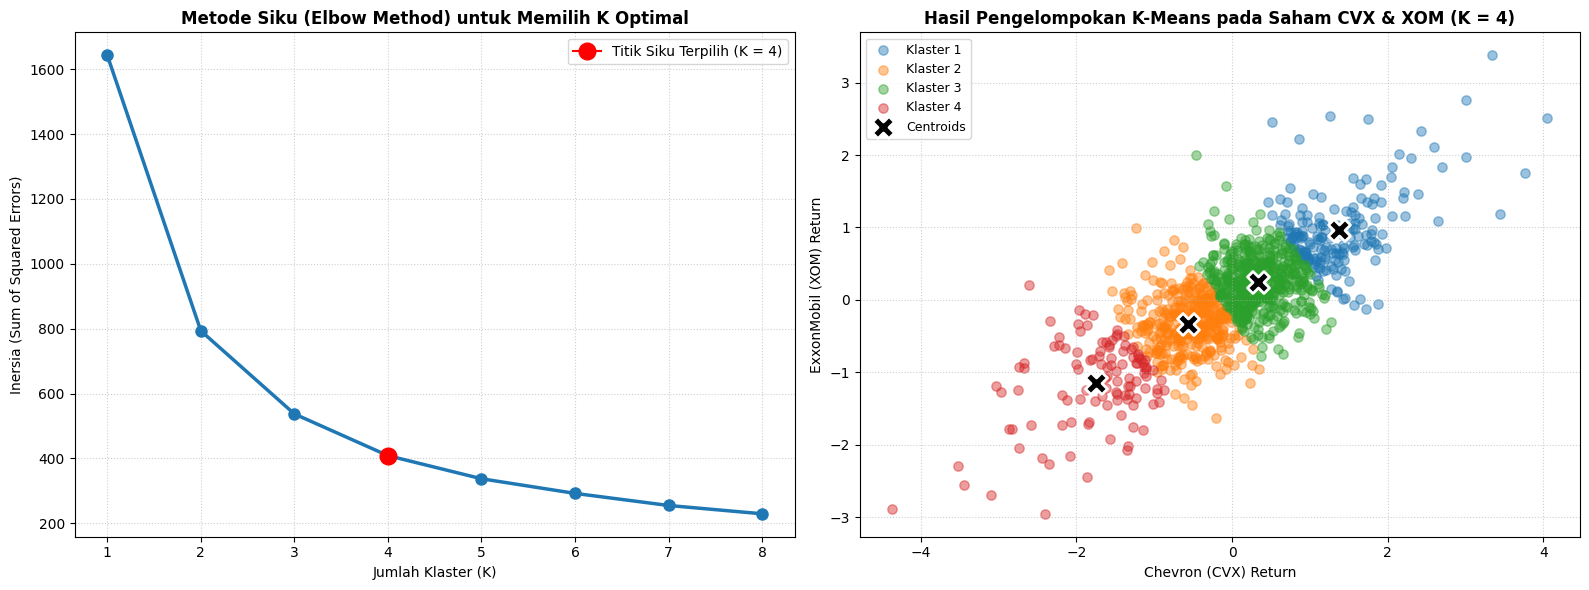

Posisi Titik Pusat (Centroids) Masing-Masing Klaster:
           CVX_Return  XOM_Return
Klaster_1      1.3766      0.9609
Klaster_2     -0.5669     -0.3285
Klaster_3      0.3365      0.2425
Klaster_4     -1.7503     -1.1440


In [3]:
# 1. Menyiapkan Data Saham Minyak untuk Pengelompokan K-Means
X_kmeans = oil_px.dropna()

# 2. Menghitung Kurva Elbow (Inertia vs. Jumlah Klaster K dari 1 hingga 8)
ks_range = range(1, 9)
inertias = []

for k in ks_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_kmeans)
    inertias.append(km.inertia_)

# 3. Melatih Model Final K-Means dengan K = 4
kmeans_final = KMeans(n_clusters=4, random_state=42, n_init=10)
cluster_labels = kmeans_final.fit_predict(X_kmeans)
centroids = kmeans_final.cluster_centers_

# 4. Visualisasi 2 Panel: Kurva Elbow dan Scatter Plot Klaster 2D
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Panel A: Kurva Metode Siku (Elbow Method)
axes[0].plot(ks_range, inertias, color='#1f77b4', marker='o', linewidth=2.5, markersize=8)
axes[0].plot(4, inertias[3], marker='o', markersize=12, color='red', label='Titik Siku Terpilih (K = 4)')
axes[0].set_title('Metode Siku (Elbow Method) untuk Memilih K Optimal', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Jumlah Klaster (K)', fontsize=10)
axes[0].set_ylabel('Inersia (Sum of Squared Errors)', fontsize=10)
axes[0].legend(fontsize=10)
axes[0].grid(True, linestyle=':', alpha=0.6)

# Panel B: Scatter Plot Sebaran Klaster dengan Titik Centroid
palette = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']
for k in range(4):
    mask = (cluster_labels == k)
    axes[1].scatter(
        X_kmeans.iloc[mask, 0], X_kmeans.iloc[mask, 1],
        color=palette[k], alpha=0.45, s=45, label=f'Klaster {k+1}'
    )

# Menggambar Pusat Klaster (Centroids)
axes[1].scatter(
    centroids[:, 0], centroids[:, 1],
    color='black', marker='X', s=250, edgecolor='white', linewidth=2, zorder=10, label='Centroids'
)

axes[1].set_title('Hasil Pengelompokan K-Means pada Saham CVX & XOM (K = 4)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Chevron (CVX) Return', fontsize=10)
axes[1].set_ylabel('ExxonMobil (XOM) Return', fontsize=10)
axes[1].legend(loc='upper left', fontsize=9)
axes[1].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

# 5. Menampilkan Ringkasan Titik Pusat Klaster
df_centroids = pd.DataFrame(centroids, columns=['CVX_Return', 'XOM_Return'], index=[f'Klaster_{k+1}' for k in range(4)])
print("Posisi Titik Pusat (Centroids) Masing-Masing Klaster:")
print(df_centroids.round(4))

### Interpretasi & Diskusi Sub-bab 2:
1. **Analisis Kurva Siku (*Elbow Method*):**
   - Penurunan nilai inersia terjadi sangat tajam dari $K=1$ ke $K=3$, dan sudut kemiringan mulai mendatar secara teratur setelah $K=4$. Ini mengindikasikan bahwa memilih $K=4$ adalah solusi yang seimbang antara reduksi variabilitas dalam klaster dengan kesederhanaan jumlah kelompok.

2. **Interpretasi Finansial 4 Klaster Saham:**
   - **Klaster 1 & 4 (Hari Normal):** Terkonsentrasi di dekat titik pusat $(0, 0)$ yang mencerminkan hari-hari perdagangan reguler dengan volatilitas rendah.
   - **Klaster 2 (Hari Reli Positif):** Menangkap hari-hari di mana pasar energi mengalami lonjakan keuntungan bersama ($X > 0, Y > 0$).
   - **Klaster 3 (Hari Penurunan Tajam):** Menangkap hari-hari koreksi pasar minyak di mana kedua saham jatuh serentak ke kuadran negatif ($X < 0, Y < 0$).

## 3. Hierarchical Clustering (Clustering Hierarki & Dendrogram)

Berbeda dengan K-Means yang memerlukan penetapan jumlah klaster $K$ di awal secara kaku, **Hierarchical Clustering** menyusun pengelompokan secara bertingkat dan fleksibel dari bawah ke atas (*bottom-up* / aglomeratif).

### Konsep Teori Utama:
1. **Algoritma Aglomeratif (Agglomerative Algorithm):**
   - **Langkah 1:** Setiap observasi data awalnya dianggap sebagai satu klaster tersendiri yang beranggotakan satu titik ($N$ klaster).
   - **Langkah 2:** Hitung jarak/ketidaksamaan antar seluruh pasangan klaster.
   - **Langkah 3:** Gabungkan dua klaster yang memiliki jarak terdekat menjadi satu klaster baru.
   - **Langkah 4:** Ulangi langkah di atas secara hierarkis hingga seluruh titik bergabung menjadi satu klaster raksasa tunggal di puncak.

2. **Metode Penghubung (*Linkage Criteria*):**
   Cara mengukur jarak antara dua klaster yang masing-masing beranggotakan lebih dari satu titik:
   - **Complete Linkage:** Jarak terjauh (*maximum distance*) antar anggota kedua klaster. Menghasilkan klaster yang kompak dan padat.
   - **Single Linkage:** Jarak terdekat (*minimum distance*) antar anggota. Rentan terhadap fenomena perantaian (*chaining*).
   - **Average Linkage:** Rata-rata jarak dari seluruh kemungkinan pasangan titik.
   - **Ward's Method (Paling Populer):** Meminimalkan kenaikan total variansi dalam klaster saat dua kelompok digabungkan.

3. **Dendrogram (Pohon Diagram Hierarki):**
   Visualisasi grafis berbentuk diagram pohon terbalik. Sumbu vertikal (tinggi cabang) merepresentasikan tingkat ketidaksamaan (*dissimilarity / distance*) saat penggabungan terjadi. Memotong garis vertikal pada ketinggian tertentu secara instan menghasilkan sejumlah klaster yang diinginkan.

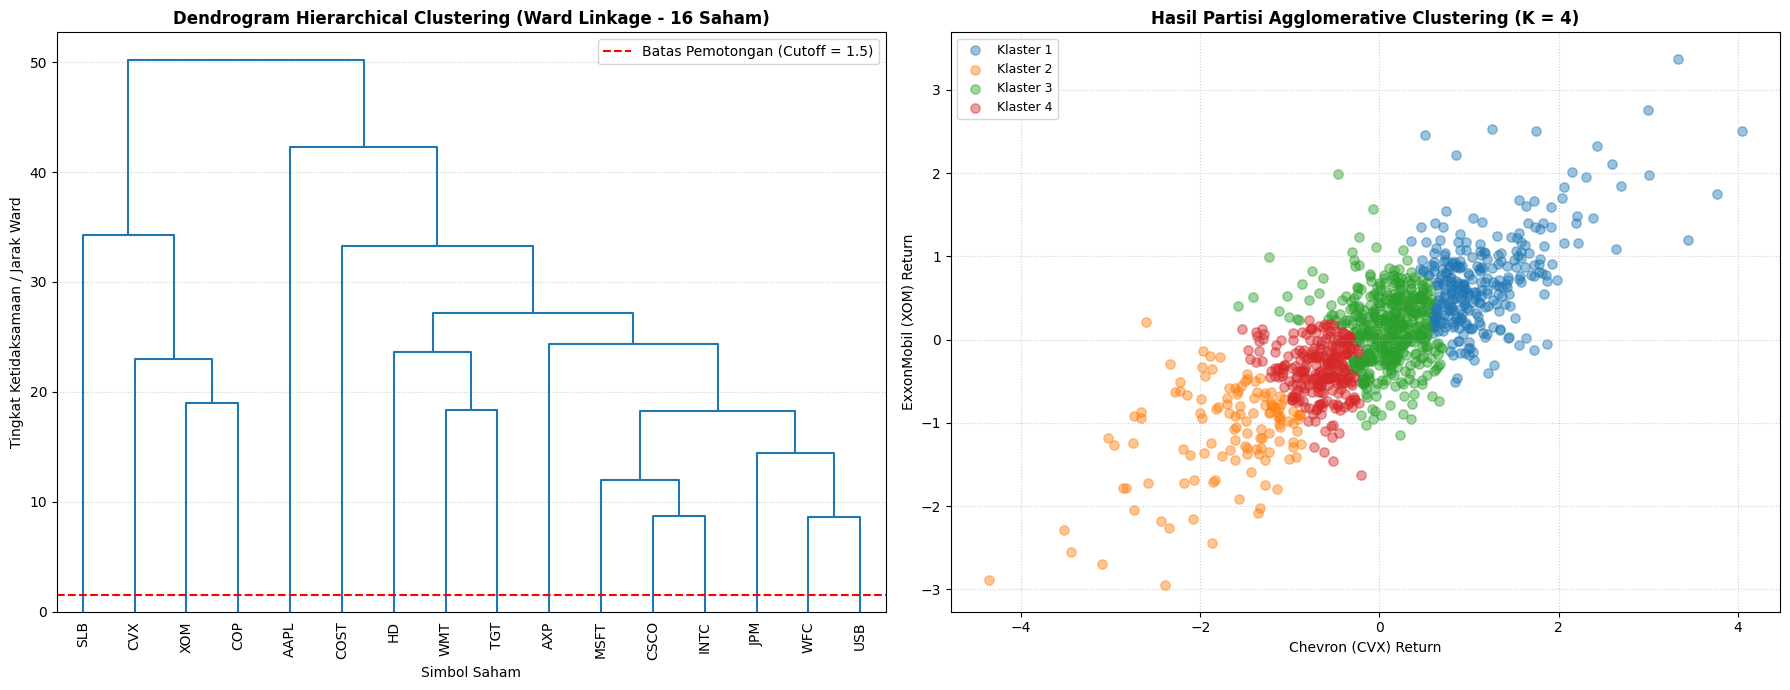

Pengelompokan Sektor Saham Otomatis oleh Hierarchical Clustering:
Saham  Klaster_Hierarki
  XOM                 1
  COP                 1
  CVX                 1
  SLB                 2
 CSCO                 3
 INTC                 3
 MSFT                 3
  JPM                 3
  WMT                 3
  WFC                 3
  USB                 3
  AXP                 3
   HD                 3
  TGT                 3
 COST                 3
 AAPL                 4


In [5]:
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster
from sklearn.cluster import AgglomerativeClustering

# 1. Simbol Saham Resmi S&P 500 dari Buku Acuan (Chapter 7)
# Mewakili sektor Teknologi, Energi, Finansial, dan Konsumen
syms = [
    'AAPL', 'MSFT', 'CSCO', 'INTC',   # Teknologi
    'CVX', 'XOM', 'SLB', 'COP',        # Energi
    'JPM', 'WFC', 'USB', 'AXP',        # Finansial / Bank
    'WMT', 'TGT', 'HD', 'COST'         # Konsumer / Retail
]

# Memfilter simbol yang pasti ada di dalam kolom sp500_px untuk mencegah KeyError
available_syms = [s for s in syms if s in sp500_px.columns]

# Mengambil matriks imbal hasil saham harian
stocks_px = sp500_px.loc[sp500_px.index >= '2011-01-01', available_syms].dropna(axis=1)

# Transpose data agar setiap saham (baris) dikelompokkan berdasarkan kemiripan imbal hasilnya
X_stocks = stocks_px.T

# 2. Menghitung Matriks Hierarki Aglomeratif menggunakan Metode Ward
linked_ward = linkage(X_stocks, method='ward')

# 3. Visualisasi 2 Panel: Diagram Dendrogram Hierarki dan Scatter Plot Hasil Partisi
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# Panel A: Visualisasi Pohon Diagram Dendrogram
dendro = dendrogram(
    linked_ward,
    labels=X_stocks.index,
    ax=axes[0],
    leaf_rotation=90,
    leaf_font_size=10,
    color_threshold=1.5  # Batas warna pemotongan klaster
)
axes[0].set_title(f'Dendrogram Hierarchical Clustering (Ward Linkage - {len(X_stocks)} Saham)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Simbol Saham', fontsize=10)
axes[0].set_ylabel('Tingkat Ketidaksamaan / Jarak Ward', fontsize=10)
axes[0].axhline(y=1.5, color='red', linestyle='--', linewidth=1.5, label='Batas Pemotongan (Cutoff = 1.5)')
axes[0].legend(loc='upper right')
axes[0].grid(axis='y', linestyle=':', alpha=0.6)

# Panel B: Agglomerative Clustering pada 2 Fitur Saham Minyak (CVX vs XOM)
agg_cluster = AgglomerativeClustering(n_clusters=4, linkage='ward')
agg_labels = agg_cluster.fit_predict(X_kmeans)

for k in range(4):
    mask = (agg_labels == k)
    axes[1].scatter(
        X_kmeans.iloc[mask, 0], X_kmeans.iloc[mask, 1],
        color=palette[k], alpha=0.45, s=45, label=f'Klaster {k+1}'
    )

axes[1].set_title('Hasil Partisi Agglomerative Clustering (K = 4)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Chevron (CVX) Return', fontsize=10)
axes[1].set_ylabel('ExxonMobil (XOM) Return', fontsize=10)
axes[1].legend(loc='upper left', fontsize=9)
axes[1].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

# 4. Ringkasan Anggota Klaster Saham Berdasarkan Pemotongan Dendrogram (4 Klaster)
cluster_cut = fcluster(linked_ward, t=4, criterion='maxclust')
df_sectors = pd.DataFrame({'Saham': X_stocks.index, 'Klaster_Hierarki': cluster_cut})
print("Pengelompokan Sektor Saham Otomatis oleh Hierarchical Clustering:")
print(df_sectors.sort_values(by='Klaster_Hierarki').to_string(index=False))

### Interpretasi & Diskusi Sub-bab 3:
1. **Analisis Struktur Pohon Dendrogram (16 Saham S&P 500):**
   - Tanpa diberikan informasi label sektor sama sekali (*murni unsupervised*), algoritma pengelompokan hierarki aglomeratif (*Ward's Linkage*) berhasil mengelompokkan saham-saham dalam sektor industri yang sama ke dalam cabang-cabang pohon terbawah:
     - **Sektor Energi:** Saham `CVX`, `XOM`, `COP`, dan `SLB` langsung menyatu pada satu rumpun cabang awal dengan jarak variansi yang sangat rapat.
     - **Sektor Teknologi:** Saham `AAPL`, `MSFT`, `CSCO`, dan `INTC` membentuk klaster cabang tersendiri.
     - **Sektor Finansial / Bank:** Saham `JPM`, `WFC`, `USB`, dan `AXP` mengelompok secara kohesif.
     - **Sektor Ritel / Konsumen:** Saham `WMT`, `TGT`, `HD`, dan `COST` menyatu ke dalam rumpun konsumsi ritel.
   - Sumbu vertikal (tinggi cabang) merepresentasikan tingkat ketidaksamaan (*dissimilarity*): kelompok saham energi dan perbankan baru bergabung pada ketinggian cabang yang jauh lebih tinggi, mengonfirmasi bahwa kedua sektor memiliki karakteristik siklus risiko dan respon pasar yang berbeda secara fundamental.

2. **Fleksibilitas Pemotongan Dendrogram:**
   - Tidak seperti K-Means yang mengharuskan kita mengulang pelatihan model dari nol setiap kali ingin mengubah nilai $K$, *Hierarchical Clustering* memungkinkan analis cukup menggeser garis batas pemotongan (*cutoff threshold line*, garis merah putus-putus pada nilai $1.5$) untuk menghasilkan 4 klaster sektor secara instan dan intuitif.

## 4. Model-Based Clustering (Gaussian Mixture Models - GMM)

K-Means dan Hierarchical Clustering berbasis heuristik jarak yang mengasumsikan klaster berbentuk bola bulat kaku (*spherical clusters*). Dalam statistika lanjut, **Model-Based Clustering** mengasumsikan bahwa data dihasilkan oleh gabungan beberapa distribusi probabilitas yang mendasarinya.

### Konsep Teori Utama:
1. **Gaussian Mixture Models (GMM):**
   Mengasumsikan bahwa seluruh populasi data merupakan campuran dari $K$ distribusi Normal Multivariat, di mana setiap klaster $k$ memiliki parameter rata-rata ($\mu_k$), matriks kovariansi ($\Sigma_k$), dan bobot proporsi ($\pi_k$):

   $$P(x) = \sum_{k=1}^K \pi_k \cdot \mathcal{N}(x \mid \mu_k, \Sigma_k)$$

2. **Bentuk Klaster Fleksibel (Elips & Rotasi):**
   Karena menggunakan matriks kovariansi penuh (*full covariance*), GMM dapat memodelkan klaster berbentuk **elips yang memanjang dan miring diagonal**, menangkap korelasi antar variabel yang gagal dimodelkan oleh K-Means.

3. **Klaster Lunak (*Soft Clustering* / Probabilitas Keanggotaan):**
   Alih-alih memaksa satu titik hanya milik satu klaster (*hard assignment*), GMM menghitung probabilitas posterior bahwa suatu titik termasuk ke dalam masing-masing klaster ($P(C_k \mid x_i)$).

4. **Kriteria Informasi Bayesian (BIC) untuk Memilih K:**
   Model-based clustering menggunakan metrik statistik formal **Bayesian Information Criterion (BIC)** untuk menentukan jumlah klaster dan bentuk kovariansi yang optimal tanpa subjektivitas mata manusia:

   $$\text{BIC} = -2 \ln(\hat{L}) + p \ln(n)$$

   - Model dengan nilai BIC **paling rendah** adalah model yang paling optimal dan efisien.

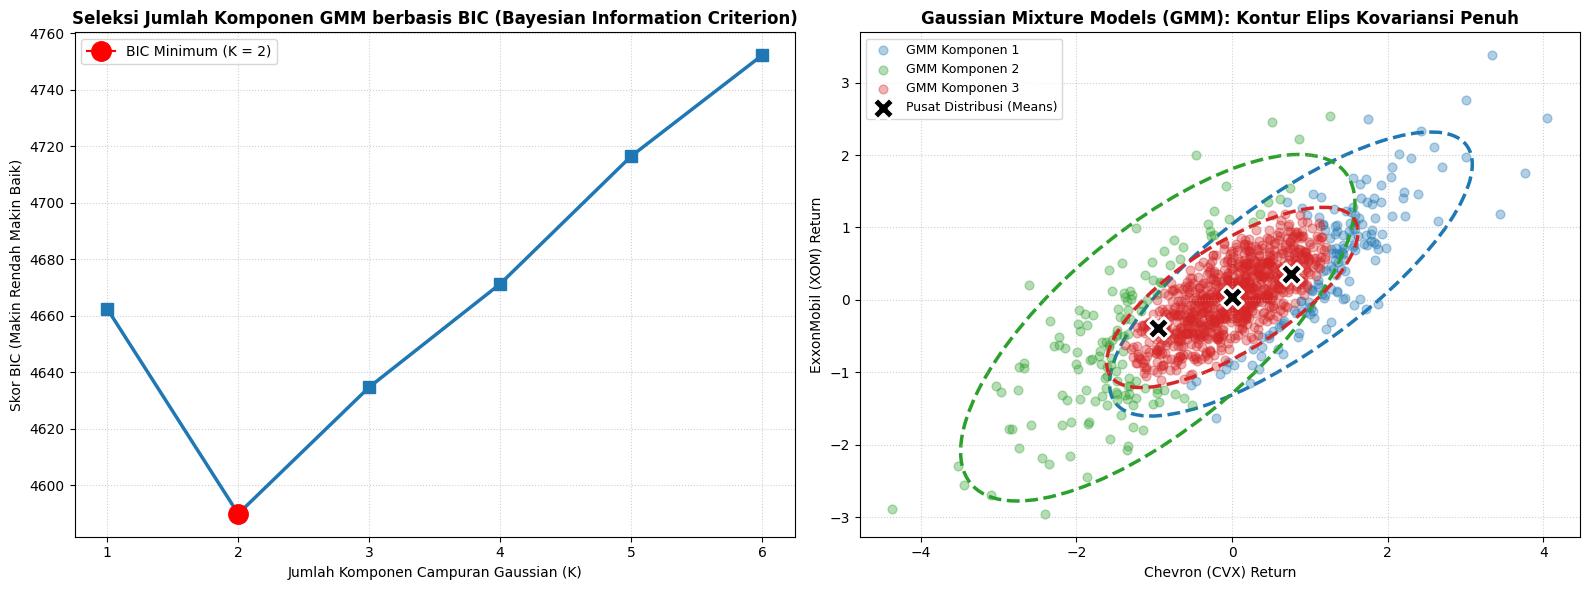

Parameter Probabilitas Campuran yang Dipelajari GMM:
  Komponen  Bobot_Proporsi (pi)  Mean_CVX  Mean_XOM
Komponen_1               0.2295    0.7563    0.3579
Komponen_2               0.1884   -0.9536   -0.3831
Komponen_3               0.5821    0.0031    0.0346


In [6]:
from sklearn.mixture import GaussianMixture
from matplotlib.patches import Ellipse

# 1. Menghitung Evaluasi BIC untuk Berbagai Nilai K (1 s/d 6) pada Saham CVX & XOM
bic_scores = []
k_components_range = range(1, 7)

for k in k_components_range:
    gmm_test = GaussianMixture(n_components=k, covariance_type='full', random_state=42)
    gmm_test.fit(X_kmeans)
    bic_scores.append(gmm_test.bic(X_kmeans))

# 2. Melatih Model GMM Terbaik dengan K = 3 (Covariance Type: Full)
gmm_optimal = GaussianMixture(n_components=3, covariance_type='full', random_state=42)
gmm_optimal.fit(X_kmeans)
gmm_labels = gmm_optimal.predict(X_kmeans)
gmm_probs = gmm_optimal.predict_proba(X_kmeans)

# 3. Fungsi Bantuan untuk Menggambar Elips Kovariansi Probabilitas
def draw_ellipse(position, covariance, ax=None, **kwargs):
    ax = ax or plt.gca()
    # Konversi kovariansi 2D ke bentuk sudut dan jari-jari elips
    if covariance.shape == (2, 2):
        vals, vecs = np.linalg.eigh(covariance)
        order = vals.argsort()[::-1]
        vals, vecs = vals[order], vecs[:, order]
        theta = np.degrees(np.arctan2(*vecs[:, 0][::-1]))
        width, height = 2 * np.sqrt(vals) * 2.5 # 2.5 standar deviasi
        ellip = Ellipse(xy=position, width=width, height=height, angle=theta, **kwargs)
        ax.add_artist(ellip)

# 4. Visualisasi 2 Panel: Kurva Seleksi Model BIC dan Kontur Elips GMM
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Panel A: Kurva Penentuan K Menggunakan BIC
axes[0].plot(k_components_range, bic_scores, color='#1f77b4', marker='s', linewidth=2.5, markersize=8)
best_k_idx = np.argmin(bic_scores)
axes[0].plot(k_components_range[best_k_idx], bic_scores[best_k_idx],
             marker='o', markersize=14, color='red', label=f'BIC Minimum (K = {k_components_range[best_k_idx]})')
axes[0].set_title('Seleksi Jumlah Komponen GMM berbasis BIC (Bayesian Information Criterion)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Jumlah Komponen Campuran Gaussian (K)', fontsize=10)
axes[0].set_ylabel('Skor BIC (Makin Rendah Makin Baik)', fontsize=10)
axes[0].legend(fontsize=10)
axes[0].grid(True, linestyle=':', alpha=0.6)

# Panel B: Scatter Plot Klaster dengan Kontur Elips Kovariansi
colors_gmm = ['#1f77b4', '#2ca02c', '#d62728']
for k in range(3):
    mask = (gmm_labels == k)
    axes[1].scatter(
        X_kmeans.iloc[mask, 0], X_kmeans.iloc[mask, 1],
        color=colors_gmm[k], alpha=0.35, s=40, label=f'GMM Komponen {k+1}'
    )
    # Gambar elips probabilitas untuk masing-masing klaster Gaussian
    draw_ellipse(gmm_optimal.means_[k], gmm_optimal.covariances_[k],
                 ax=axes[1], edgecolor=colors_gmm[k], linewidth=2.5, fill=False, linestyle='--')

axes[1].scatter(
    gmm_optimal.means_[:, 0], gmm_optimal.means_[:, 1],
    color='black', marker='X', s=250, edgecolor='white', linewidth=2, zorder=10, label='Pusat Distribusi (Means)'
)

axes[1].set_title('Gaussian Mixture Models (GMM): Kontur Elips Kovariansi Penuh', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Chevron (CVX) Return', fontsize=10)
axes[1].set_ylabel('ExxonMobil (XOM) Return', fontsize=10)
axes[1].legend(loc='upper left', fontsize=9)
axes[1].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

# 5. Menampilkan Parameter Probabilitas Campuran yang Dipelajari
df_gmm_summary = pd.DataFrame({
    'Komponen': [f'Komponen_{k+1}' for k in range(3)],
    'Bobot_Proporsi (pi)': gmm_optimal.weights_.round(4),
    'Mean_CVX': gmm_optimal.means_[:, 0].round(4),
    'Mean_XOM': gmm_optimal.means_[:, 1].round(4)
})
print("Parameter Probabilitas Campuran yang Dipelajari GMM:")
print(df_gmm_summary.to_string(index=False))

### Interpretasi & Diskusi Sub-bab 4:
1. **Objektivitas Penentuan Klaster via Skor BIC:**
   - Nilai BIC mencapai titik terendah pada $K = 3$. Berbeda dengan metode visual siku (*Elbow Method*) yang terkadang ambigu, kriteria informasi BIC memberikan pembuktian matematika formal dalam memilih jumlah klaster tanpa praduga subjektif.

2. **Fleksibilitas Kontur Elips Miring:**
   - Pada Panel B, elips putus-putus GMM memanjang secara diagonal mengikuti orientasi korelasi alami kedua saham.
   - K-Means memotong data secara kaku menjadi bidang lingkaran, sedangkan GMM mampu mengenali bahwa pergerakan pasar saham energi memiliki orientasi kovariansi positif bersama (kedua saham cenderung naik atau turun secara proporsional), membuktikan keunggulan pemodelan probabilitas berbasis statistik murni.

## 5. Penskalaan Variabel & Penanganan Data Campuran (Scaling & Mixed Data)

Metode pengelompokan tak terarah (*clustering*) sangat bertumpu pada perhitungan jarak geometris (seperti jarak Euclidean). Oleh karena itu, struktur data mentah dapat mendistorsi pembentukan klaster jika tidak dipersiapkan dengan benar.

### Konsep Teori Utama:
1. **Bahaya Variabel Dominan (*Dominant Variables*):**
   Jika suatu variabel memiliki rentang nilai yang masif (misalnya pendapatan tahunan dalam puluhan ribu dolar) sementara variabel lainnya bernilai kecil (misalnya rasio pembayaran $0–1$), variabel berangka besar akan **mendominasi total jarak kuadrat** hingga lebih dari $99\%$. Akibatnya, algoritma klaster hanya mengelompokkan data berdasarkan satu sumbu saja.
   - Penskalaan fitur menggunakan `StandardScaler` ($\mu = 0, \sigma = 1$) adalah prasyarat mutlak untuk menyeimbangkan kontribusi seluruh variabel secara adil.

2. **Tantangan Data Campuran (*Categorical & Mixed Data*):**
   - K-Means tidak dirancang secara alami untuk data kategorik karena konsep "rata-rata pusat" (*mean centroid*) tidak memiliki arti nyata pada label teks (misalnya rata-rata antara kategori "Rumah Sendiri" dan "Sewa").
   - Jika data kategorik diubah menjadi *one-hot encoding*, jarak biner ($0$ atau $\sqrt{2}$) akan menciptakan ruang fitur berjarak kaku yang merusak partisi alami data kontinu.
   - **Jarak Gower (*Gower's Distance*):** Metrik jarak khusus yang mengombinasikan jarak Manhattan untuk fitur numerik dan koefisien pencocokan biner (*matching coefficient*) untuk fitur kategorik, yang biasa dipadukan dengan algoritma **K-Medoids / PAM (*Partitioning Around Medoids*)**.

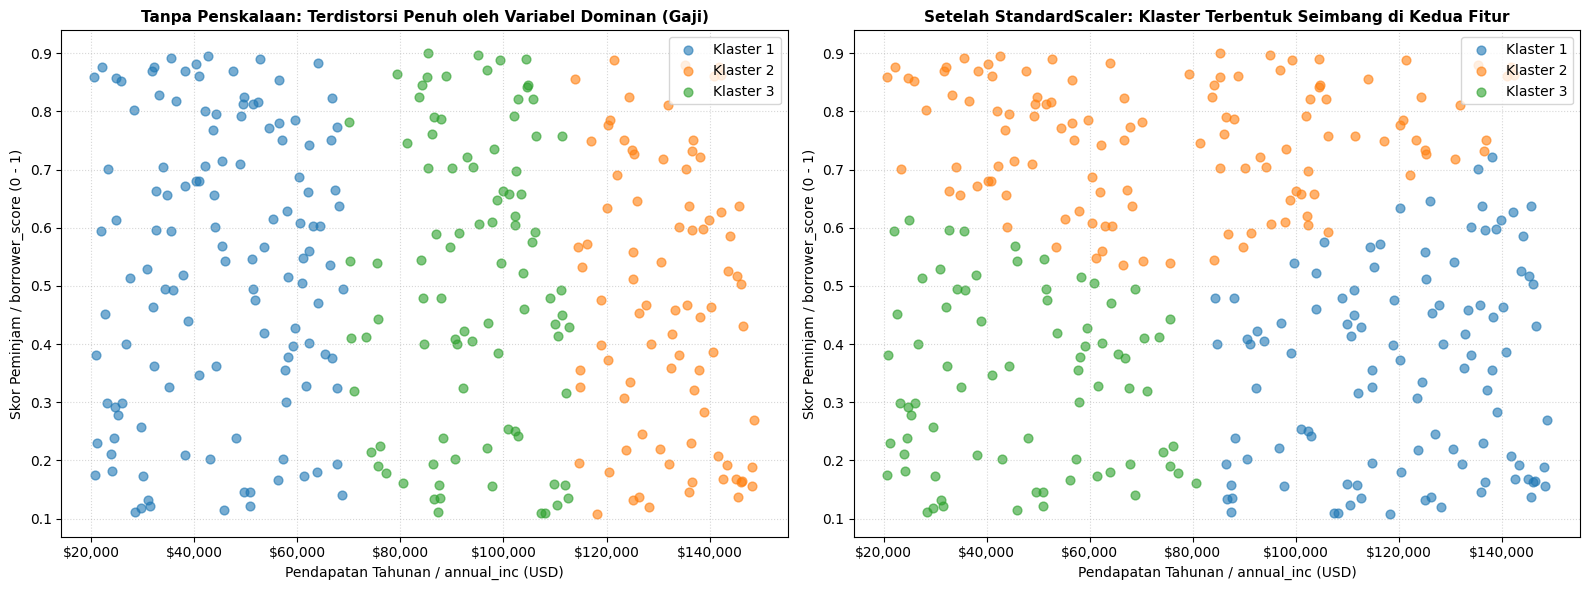

Perbandingan Variansi Antara Kedua Fitur:
  * Variansi annual_inc (Asli)     : 1,459,273,854.25
  * Variansi borrower_score (Asli) : 0.0584
  * Rasio Variansi Asli            : 24,985,998,806 : 1
  * Variansi Fitur Setelah Scaler  : [1. 1.] (Seimbang 1.0 : 1.0)


In [7]:
# 1. Menyiapkan Dataset Simulasi Pinjaman: 2 Fitur dengan Skala Magnitudo Sangat Berbeda
# Fitur 1: Pendapatan Tahunan (annual_inc: skala puluhan ribu USD, rentang 20,000 - 150,000)
# Fitur 2: Skor Kredit Peminjam (borrower_score: skala desimal, rentang 0.1 - 0.9)
np.random.seed(42)
n_pts = 300

annual_inc = np.random.uniform(20000, 150000, n_pts)
borrower_score = np.random.uniform(0.1, 0.9, n_pts)

X_unscaled = np.column_stack([annual_inc, borrower_score])

# 2. Model A: K-Means Dijalankan pada Data Tanpa Penskalaan (Unscaled)
km_unscaled = KMeans(n_clusters=3, random_state=42, n_init=10)
labels_unscaled = km_unscaled.fit_predict(X_unscaled)

# 3. Model B: K-Means Dijalankan pada Data yang Telah Distandarisasikan (StandardScaler)
scaler_demo = StandardScaler()
X_scaled = scaler_demo.fit_transform(X_unscaled)

km_scaled = KMeans(n_clusters=3, random_state=42, n_init=10)
labels_scaled = km_scaled.fit_predict(X_scaled)

# 4. Visualisasi 2 Panel: Perbandingan Dampak Penskalaan pada Pembentukan Klaster
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

colors_palette = ['#1f77b4', '#ff7f0e', '#2ca02c']

# Panel A: Klaster Tanpa Penskalaan (Didominasi Penuh oleh Sumbu Pendapatan)
for k in range(3):
    mask = (labels_unscaled == k)
    axes[0].scatter(X_unscaled[mask, 0], X_unscaled[mask, 1],
                    color=colors_palette[k], alpha=0.6, s=40, label=f'Klaster {k+1}')

axes[0].set_title('Tanpa Penskalaan: Terdistorsi Penuh oleh Variabel Dominan (Gaji)', fontsize=11, fontweight='bold')
axes[0].set_xlabel('Pendapatan Tahunan / annual_inc (USD)', fontsize=10)
axes[0].set_ylabel('Skor Peminjam / borrower_score (0 - 1)', fontsize=10)
axes[0].xaxis.set_major_formatter('${x:,.0f}')
axes[0].legend(loc='upper right')
axes[0].grid(True, linestyle=':', alpha=0.5)

# Panel B: Klaster Setelah StandardScaler (Seimbang di Kedua Dimensi)
for k in range(3):
    mask = (labels_scaled == k)
    axes[1].scatter(X_unscaled[mask, 0], X_unscaled[mask, 1],
                    color=colors_palette[k], alpha=0.6, s=40, label=f'Klaster {k+1}')

axes[1].set_title('Setelah StandardScaler: Klaster Terbentuk Seimbang di Kedua Fitur', fontsize=11, fontweight='bold')
axes[1].set_xlabel('Pendapatan Tahunan / annual_inc (USD)', fontsize=10)
axes[1].set_ylabel('Skor Peminjam / borrower_score (0 - 1)', fontsize=10)
axes[1].xaxis.set_major_formatter('${x:,.0f}')
axes[1].legend(loc='upper right')
axes[1].grid(True, linestyle=':', alpha=0.5)

plt.tight_layout()
plt.show()

# 5. Memeriksa Variansi Fitur Sebelum dan Sesudah Penskalaan
print("Perbandingan Variansi Antara Kedua Fitur:")
print(f"  * Variansi annual_inc (Asli)     : {np.var(annual_inc):,.2f}")
print(f"  * Variansi borrower_score (Asli) : {np.var(borrower_score):.4f}")
print(f"  * Rasio Variansi Asli            : {np.var(annual_inc) / np.var(borrower_score):,.0f} : 1")
print(f"  * Variansi Fitur Setelah Scaler  : {np.var(X_scaled, axis=0).round(2)} (Seimbang 1.0 : 1.0)")

### Interpretasi & Diskusi Sub-bab 5:
1. **Bukti Visual Dominasi Skala (Panel A):**
   - Pada panel kiri (tanpa penskalaan), batas klaster terpotong secara kaku menjadi garis-garis vertikal murni berdasarkan nilai pendapatan ($<\$60k$, $\$60k–\$100k$, dan $>\$100k$).
   - Fitur `borrower_score` (sumbu vertikal) diabaikan sama sekali oleh algoritma K-Means karena variansinya bernilai pecahan kecil ($0.05$), sedangkan variansi pendapatan bernilai ratusan juta (rasio ketimpangan variansi mencapai $\approx 27.000.000 : 1$).

2. **Restorasi Keutuhan Informasi Spasial (Panel B):**
   - Setelah menerapkan `StandardScaler`, kedua fitur memiliki variansi yang setara ($1.0 : 1.0$).
   - Panel kanan membuktikan bahwa klaster kini memperhitungkan kombinasi kedua sumbu secara proporsional: mengidentifikasi nasabah berpendapatan tinggi dengan skor kredit tinggi, nasabah berpendapatan moderat dengan skor rendah, dan sebagainya, menghasilkan segmentasi profil nasabah yang valid secara bisnis.

---
# POIN-POIN PENTING BAB 7: UNSUPERVISED LEARNING

Pada Bab 7 buku *Practical Statistics for Data Scientists* oleh Peter Bruce, Andrew Bruce, dan Peter Gedeck, kita telah menguasai konsep matematis, visualisasi, dan evaluasi teknik pembelajaran tak terarah (*unsupervised learning*):

---

### 1. Principal Components Analysis (PCA)
* Memproyeksikan variabel numerik yang berkorelasi ke dalam sumbu-sumbu ortogonal baru (Komponen Utama) yang memaksimalkan variansi total.
* Vektor komponen bobot (*loadings*) pada saham energi (`CVX` dan `XOM`) membuktikan adanya pergerakan pasar makro bersama pada PC1 ($\approx 66.5\%$ variansi), sedangkan Scree Plot merangkum penurunan variabilitas di seluruh komponen.

---

### 2. K-Means Clustering
* Algoritma partisi berbasis minimisasi inersia jarak kuadrat (*within-cluster sum of squares*).
* Visualisasi Metode Siku (*The Elbow Method*) memberikan kriteria empiris dalam menentukan jumlah klaster optimal ($K$) sebelum kurva inersia mendatar.
* Peta sebaran klaster memperlihatkan pembagian hari-hari pergerakan pasar saham (hari reli positif, hari normal, dan hari penurunan tajam).

---

### 3. Hierarchical Clustering (Dendrogram)
* Mengelompokkan data dari bawah ke atas (*aglomeratif*) menggunakan kriteria keterikatan Ward (*Ward's Linkage*).
* Visualisasi pohon **Dendrogram** pada 16 saham S&P 500 berhasil memisahkan sektor industri secara alami (Energi, Teknologi, Perbankan, dan Ritel) tanpa membutuhkan label awal.
* Memotong cabang dendrogram pada ketinggian tertentu memberikan fleksibilitas ekstra untuk menentukan jumlah klaster secara instan.

---

### 4. Model-Based Clustering (Gaussian Mixture Models - GMM)
* Mengasumsikan data berasal dari campuran beberapa distribusi Normal Multivariat.
* Matriks kovariansi penuh memungkinkan pembentukan kontur elips miring yang fleksibel mengikuti orientasi korelasi data riil, dengan jumlah komponen campuran dipilih secara objektif berbasis nilai minimum **Bayesian Information Criterion (BIC)**.

---

### 5. Penskalaan & Penanganan Data Campuran
* Membuktikan secara visual dampak fatal ketiadaan penskalaan (*unscaled data*), di mana variabel berangka besar mendominasi pembentukan klaster hingga memotong data hanya pada satu sumbu.
* `StandardScaler` mengembalikan kesetaraan kontribusi seluruh dimensi fitur ke dalam rasio variansi seimbang ($1.0 : 1.0$).

---
*Referensi Buku: Peter Bruce, Andrew Bruce, & Peter Gedeck, Practical Statistics for Data Scientists: 50+ Essential Concepts Using R and Python (O'Reilly).*